# Experiment 5: DiagScale during continued pretraining

Forty-eight runs adapt only query-scaling parameters across credit tables: two model families, three adapter learning rates, four dataset partitions and two tasks. Original backbone weights stay unchanged. The objective is transfer to excluded tables, rather than target-table fine-tuning.

## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
from src.visualize import adapter_study as ds, publication as pub, pilots as pv
sink = FigureSaver('experiment5/01_training')
report = cp.NotebookReport('Experiment 5: DiagScale during continued pretraining', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description())
runs = [cp.load_campaign(5, track) for track in ('pd', 'lgd')]

DATA: output CreditPFN.zip; modified 2026-10-13T12:13:29+00:00; read only.
Project: output CreditPFN; modified 2026-10-13T13:56:42+00:00; read only.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Adapter recipe and training coverage

,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; origina...
1,Training,Cross-table CPT; target table excluded from ch...
2,Grid,2 bases × 3 adapter rates × 4 dataset partitio...
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both d...
6,Budget,"10,000 successful updates; seed 42"
7,Regularization,AdamW decay on zero-centered deltas; no L2-SP
8,Parameter movement,RMS query-scale delta; not relative backbone-w...
9,Interpretation,Recipe-level comparison against the base; not ...


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,0,DATA manifests
2,Epoch rows,0,Project training diagnostics
3,Milestone rows,0,Project trajectory diagnostics
4,Benchmark folds,0,Project final evaluation


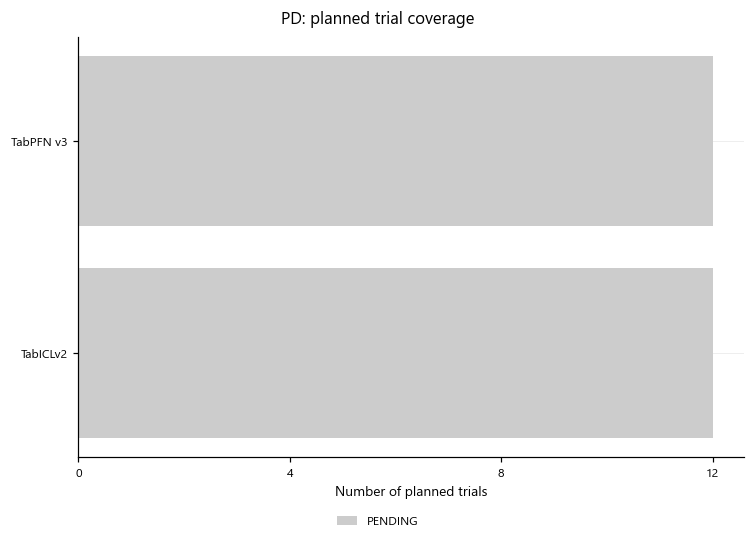

PD. Recorded status of 24 planned PD trials by base model. PENDING denotes no manifest outcome and can include currently running or queued jobs. INTERRUPTED denotes saved progress, not a numerical failure. This figure does not query the scheduler.

,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; origina...
1,Training,Cross-table CPT; target table excluded from ch...
2,Grid,2 bases × 3 adapter rates × 4 dataset partitio...
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both d...
6,Budget,"10,000 successful updates; seed 42"
7,Regularization,AdamW decay on zero-centered deltas; no L2-SP
8,Parameter movement,RMS query-scale delta; not relative backbone-w...
9,Interpretation,Recipe-level comparison against the base; not ...


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,0,DATA manifests
2,Epoch rows,0,Project training diagnostics
3,Milestone rows,0,Project trajectory diagnostics
4,Benchmark folds,0,Project final evaluation


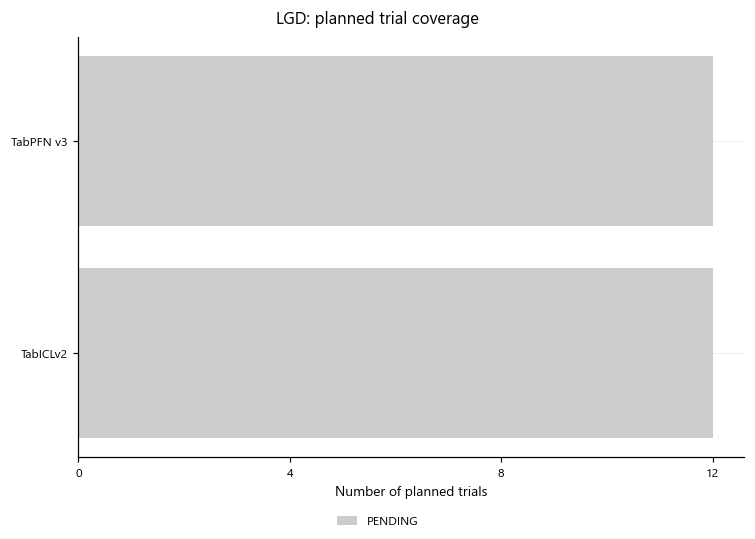

LGD. Recorded status of 24 planned LGD trials by base model. PENDING denotes no manifest outcome and can include currently running or queued jobs. INTERRUPTED denotes saved progress, not a numerical failure. This figure does not query the scheduler.

In [2]:
for run in runs:
    report.table(run.track.upper()+' protocol', ds.protocol_table(run))
    report.table(run.track.upper()+' evidence', pub.availability(run))
    cp.show(sink, cp.plot_coverage(run), track=run.track)
report.add('1. Adapter recipe and training coverage', 'Only optimizer-selected scale deltas are updated. TabICL can retain backbone autograd flags without placing backbone tensors in the optimizer. Completed training does not establish completed evaluation.')

## 2. Loss, gradients and query-scale movement

Each model receives a compact four-panel dashboard. Curves average all four training-dataset partitions at each adapter rate. Loss stays on its native architecture-specific scale. RMS adapter movement is measured from identity scaling; relative movement from zero-valued deltas is undefined.

In [3]:
for run in runs:
    cp.show(sink, ds.plot_optimization(run))
    report.table(run.track.upper()+' numerical health', pv.health_table(run))
    for label, table in cp.loss_coverage_tables(run).items():
        report.table(run.track.upper()+' '+label, table)
report.add('2. Loss, gradients and query-scale movement', 'Zero L2-SP is not plotted as an effect. AdamW decays zero-centered deltas. Clipping concerns adapter gradients in both classification and regression; unavailable measurements remain gaps.')

No measurements available for this section yet.


""


""


No measurements available for this section yet.


""


""


## 3. Credit transfer and non-credit retention

Monitor AUC for PD and R² for LGD at fixed milestones. These small-context monitors describe learning dynamics; they do not replace the final five-fold benchmark.

In [4]:
for run in runs:
    cp.show(sink, ds.plot_monitors(run))
report.add('3. Credit transfer and non-credit retention', 'Each table is paired with its own update-zero score. A complete baseline cohort and every planned partition are required. Repeated non-credit observations are averaged within table before equal-table aggregation.')

No measurements available for this section yet.
No measurements available for this section yet.


## 4. Applied schedule and computational cost

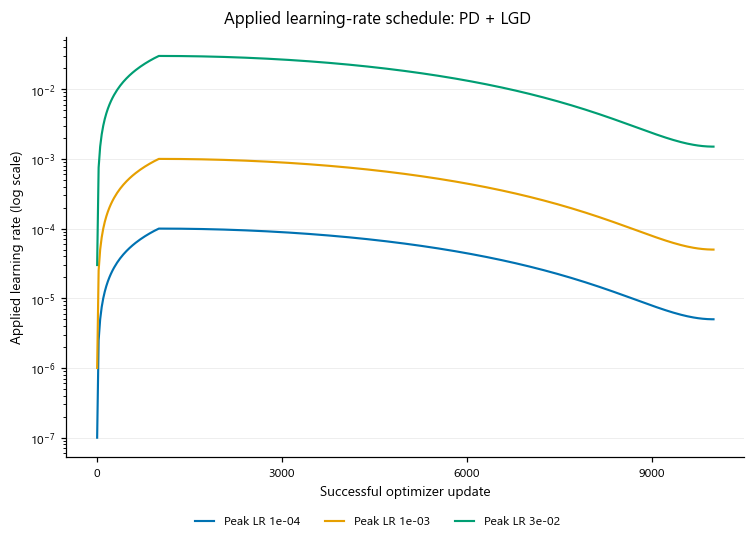

Learning rates evaluated from the recorded campaign configuration using the training scheduler. Each distinct peak-rate schedule is drawn once, pooling tasks only when budget, warmup and decay floor agree. The rate for update u is the scheduler value before that update (index u minus one). The first update has zero learning rate and is omitted from the logarithmic axis, but retained in the table. These are configured schedules; measured epoch-end rates and their sampling intervals are reported separately.

,trial_name,base,learning_rate,partition,status
0,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,0,PENDING
1,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,0,PENDING
2,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,0,PENDING
3,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,0,PENDING
4,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0010,0,PENDING
5,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0300,0,PENDING
6,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,1,PENDING
7,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,1,PENDING
8,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,1,PENDING
9,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,1,PENDING


No measurements available for this section yet.


,trial_name,base,learning_rate,partition,status
0,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,0,PENDING
1,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,0,PENDING
2,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,0,PENDING
3,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,0,PENDING
4,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0010,0,PENDING
5,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0300,0,PENDING
6,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,1,PENDING
7,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,1,PENDING
8,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,1,PENDING
9,cpt_diagscale_v1_s01_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,1,PENDING


No measurements available for this section yet.


In [5]:
cp.show(sink, pv.plot_schedule(runs))
for run in runs:
    report.table(run.track.upper()+' optimizer parameters and training cost', ds.costs(run))
    cp.show(sink, ds.plot_resources(run))
report.add('4. Applied schedule and computational cost', 'The common schedule is shown once for PD/LGD. Device utilization and memory are sampled observations, not integrated energy. Original-weight preservation is certified by experiment-0 checks, not inferred from low drift. Final predictive comparisons belong in the results notebook.')

## Complete text summary

All displayed numerical values and captions, in section order.

In [6]:
print(report.summary(sink))

Experiment 5: DiagScale during continued pretraining

0. Evidence and scope
DATA: output CreditPFN.zip; modified 2026-10-13T12:13:29+00:00; read only.
Project: output CreditPFN; modified 2026-10-13T13:56:42+00:00; read only.
Missing project records are unavailable evidence, not zero effects or failed training.

1. Adapter recipe and training coverage
Only optimizer-selected scale deltas are updated. TabICL can retain backbone autograd flags without placing backbone tensors in the optimizer. Completed training does not establish completed evaluation.

Table: PD protocol
CSV (first column: row index)
row,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; original weights unchanged
1,Training,Cross-table CPT; target table excluded from checkpoint training
2,Grid,2 bases × 3 adapter rates × 4 dataset partitions per task; 48 trials across PD/LGD
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both disable 